In [1]:
import pandas as pd

df = pd.read_csv("data/student-por-github.csv")

df.head()



,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [2]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      649 non-null    object
 1   sex         649 non-null    object
 2   age         649 non-null    int64 
 3   address     649 non-null    object
 4   famsize     649 non-null    object
 5   Pstatus     649 non-null    object
 6   Medu        649 non-null    int64 
 7   Fedu        649 non-null    int64 
 8   Mjob        649 non-null    object
 9   Fjob        649 non-null    object
 10  reason      649 non-null    object
 11  guardian    649 non-null    object
 12  traveltime  649 non-null    int64 
 13  studytime   649 non-null    int64 
 14  failures    649 non-null    int64 
 15  schoolsup   649 non-null    object
 16  famsup      649 non-null    object
 17  paid        649 non-null    object
 18  activities  649 non-null    object
 19  nursery     649 non-null    object
 20  higher    

In [3]:
df.describe()


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000
mean,16.744222,2.514638,2.306626,1.568567,1.930663,0.221880,3.930663,3.180277,3.184900,1.502311,2.280431,3.536210,3.659476,11.399076,11.570108,11.906009
std,1.218138,1.134552,1.099931,0.748660,0.829510,0.593235,0.955717,1.051093,1.175766,0.924834,1.284380,1.446259,4.640759,2.745265,2.913639,3.230656
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,16.000000,2.000000,1.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,2.000000,0.000000,10.000000,10.000000,10.000000
50%,17.000000,2.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,2.000000,11.000000,11.000000,12.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,6.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,32.000000,19.000000,19.000000,19.000000


In [4]:
df.isnull().sum()


school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

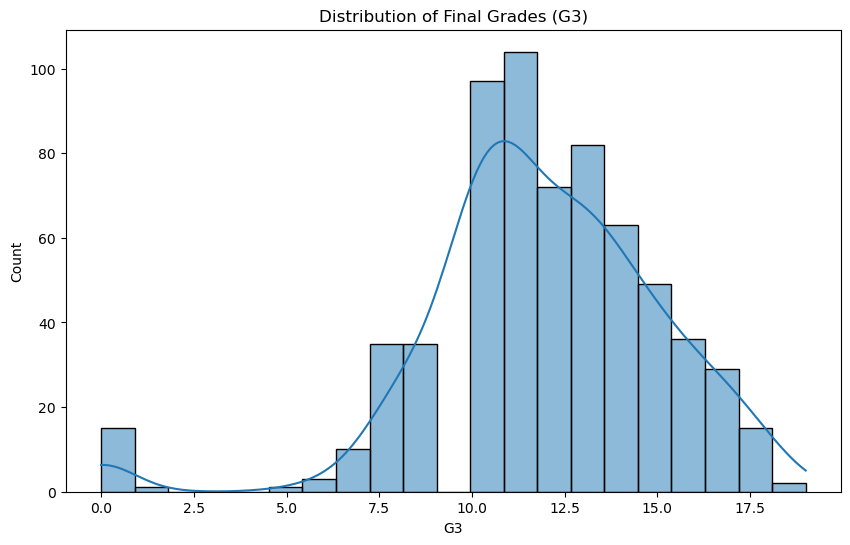

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))
sns.histplot(df["G3"], kde=True)
plt.title("Distribution of Final Grades (G3)")
plt.show()


In [6]:
numeric_df = df.select_dtypes(include=['int64', 'float64'])
numeric_df.head()


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,18,4,4,2,2,0,4,3,4,1,1,3,4,0,11,11
1,17,1,1,1,2,0,5,3,3,1,1,3,2,9,11,11
2,15,1,1,1,2,0,4,3,2,2,3,3,6,12,13,12
3,15,4,2,1,3,0,3,2,2,1,1,5,0,14,14,14
4,16,3,3,1,2,0,4,3,2,1,2,5,0,11,13,13


In [7]:
X = numeric_df.drop("G3", axis=1)
y = numeric_df["G3"]


In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


In [9]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)


LinearRegression()

In [10]:
from sklearn.metrics import mean_absolute_error, r2_score

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

mae, r2


(0.7348086550074662, 0.860477588128216)

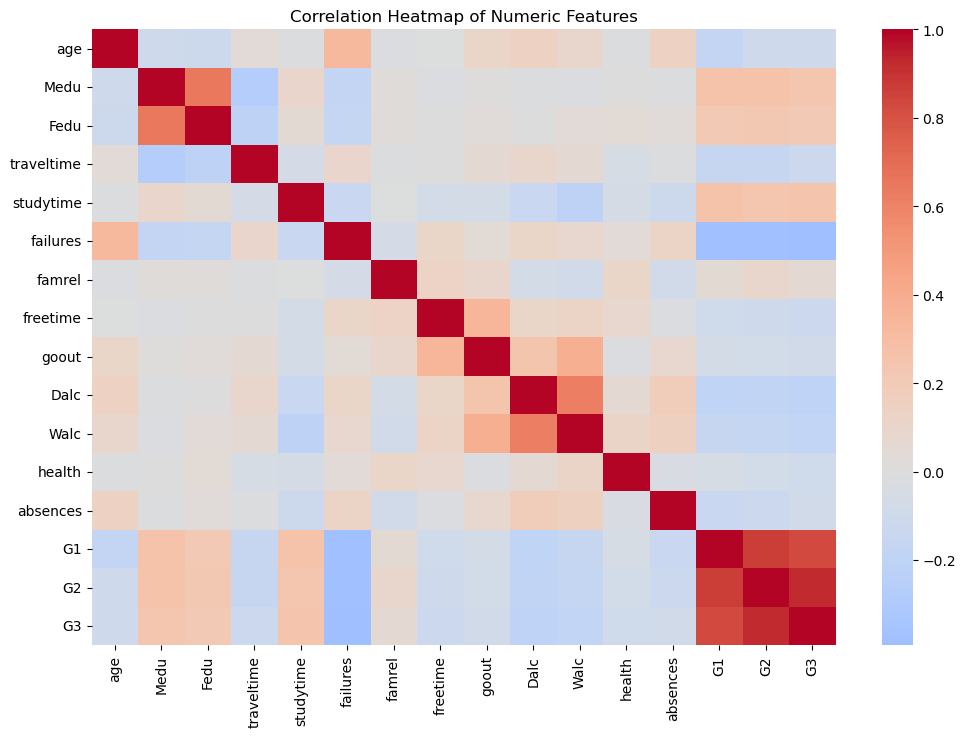

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))
corr = numeric_df.corr()
sns.heatmap(corr, annot=False, cmap="coolwarm", center=0)
plt.title("Correlation Heatmap of Numeric Features")
plt.show()


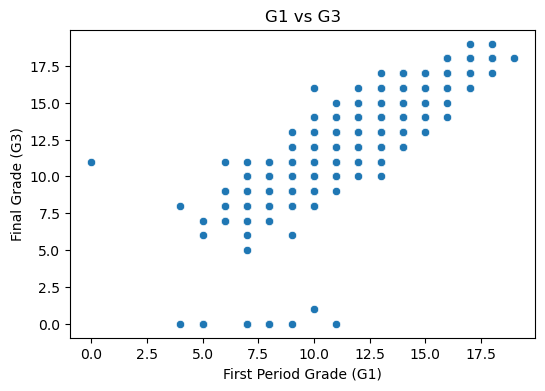

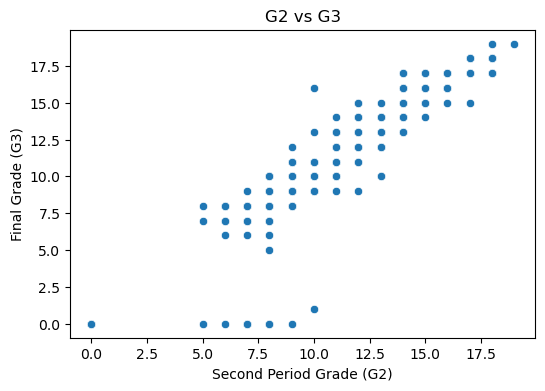

In [12]:
plt.figure(figsize=(6,4))
sns.scatterplot(x=df["G1"], y=df["G3"])
plt.xlabel("First Period Grade (G1)")
plt.ylabel("Final Grade (G3)")
plt.title("G1 vs G3")
plt.show()

plt.figure(figsize=(6,4))
sns.scatterplot(x=df["G2"], y=df["G3"])
plt.xlabel("Second Period Grade (G2)")
plt.ylabel("Final Grade (G3)")
plt.title("G2 vs G3")
plt.show()


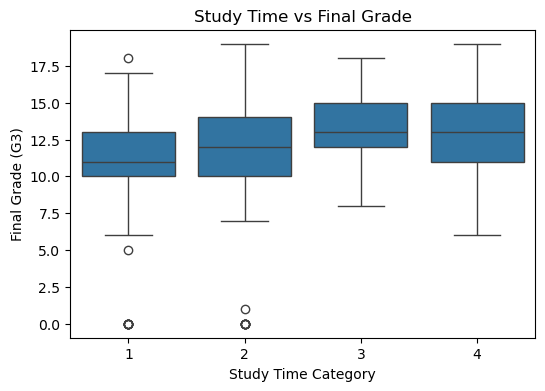

In [13]:
plt.figure(figsize=(6,4))
sns.boxplot(x=df["studytime"], y=df["G3"])
plt.xlabel("Study Time Category")
plt.ylabel("Final Grade (G3)")
plt.title("Study Time vs Final Grade")
plt.show()


In [14]:
from sklearn.metrics import mean_absolute_error, r2_score

def evaluate_model(model, X_train, y_train, X_test, y_test, name="model"):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    print(f"{name}: MAE = {mae:.2f}, R2 = {r2:.3f}")
    return name, mae, r2


In [15]:
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()

results = []   # list to store the results

results.append(
    evaluate_model(lin_reg, X_train, y_train, X_test, y_test, "Linear Regression")
)


Linear Regression: MAE = 0.73, R2 = 0.860


In [16]:
from sklearn.tree import DecisionTreeRegressor

tree = DecisionTreeRegressor(
    random_state=42,
    max_depth=5   # choose a reasonable tree depth
)

results.append(
    evaluate_model(tree, X_train, y_train, X_test, y_test, "Decision Tree (depth=5)")
)


Decision Tree (depth=5): MAE = 0.78, R2 = 0.827


In [17]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=200,   # number of trees
    random_state=42,
    n_jobs=-1           # use all CPU cores for speed
)

results.append(
    evaluate_model(rf, X_train, y_train, X_test, y_test, "Random Forest")
)


Random Forest: MAE = 0.76, R2 = 0.839


In [18]:
import pandas as pd

results_df = pd.DataFrame(results, columns=["model", "mae", "r2"])
results_df


,model,mae,r2
0,Linear Regression,0.734809,0.860478
1,Decision Tree (depth=5),0.784720,0.826976
2,Random Forest,0.762115,0.839349


In [19]:
import pandas as pd

df = pd.read_csv("data/student-por-github.csv")

print("Number of students:", len(df))
print("Number of columns:", len(df.columns))

Number of students: 649
Number of columns: 33


In [20]:
print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())


Dataset shape: (649, 33)
Missing values: 0
Duplicate rows: 0


In [21]:
import pandas as pd

df = pd.read_csv("data/student-por-github.csv")

print("CSV file loaded successfully!")
print("Number of students:", len(df))
print("Number of columns:", len(df.columns))

CSV file loaded successfully!
Number of students: 649
Number of columns: 33


In [22]:
import os

print(os.getcwd())

C:\Users\Nisrine Zaghar\Learning-analytics-model


In [23]:
import pandas as pd

df = pd.read_csv("data/student-por-github.csv")

print("Dataset loaded successfully!")
print("Number of students:", len(df))
print("Number of columns:", len(df.columns))

df.head()

Dataset loaded successfully!
Number of students: 649
Number of columns: 33


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [24]:
from pathlib import Path

file_path = Path("data/student-por-github.csv")

print("Dataset exists:", file_path.exists())
print("Dataset location:", file_path.resolve())

Dataset exists: True
Dataset location: C:\Users\Nisrine Zaghar\Learning-analytics-model\data\student-por-github.csv


In [25]:
import pandas as pd

df = pd.read_csv("data/student-por-github.csv")

print("Dataset loaded successfully!")
print("Number of students:", len(df))
print("Number of columns:", len(df.columns))


Dataset loaded successfully!
Number of students: 649
Number of columns: 33


In [26]:
import pandas as pd

df = pd.read_csv("data/student-por-github.csv")

print("Number of students:", len(df))
print("Number of columns:", len(df.columns))

Number of students: 649
Number of columns: 33
